# Лабораторна робота 3. Робота з нейронними мережами. Навчання мережі
**Бібліотека:** TensorFlow / Keras · **Середовище:** Google Colaboratory · **Набір даних:** MNIST (70 000 рукописних цифр 28×28)

Мета: побудувати повнозв'язну нейронну мережу, навчити її розпізнавати рукописні цифри, оцінити точність і дослідити, як на результат впливають розмір вибірки, кількість нейронів, епох і шарів.

## 1. Підключення бібліотек

In [1]:
# Підключаємо бібліотеки
import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt

# Фіксуємо зерно генератора випадкових чисел, щоб результати повторювались
keras.utils.set_random_seed(42)

print('Версія TensorFlow:', tf.__version__)
print('Бібліотеки підключено успішно!')

Версія TensorFlow: 2.21.0
Бібліотеки підключено успішно!


## 2. Завантаження набору даних MNIST

In [2]:
# Keras сам завантажує MNIST і ділить його на навчальну та тестову частини
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

print('Навчальних зображень:', x_train.shape[0])
print('Тестових зображень:  ', x_test.shape[0])
print('Розмір зображення:   ', x_train.shape[1], 'x', x_train.shape[2], 'пікселів')

Навчальних зображень: 60000
Тестових зображень:   10000
Розмір зображення:    28 x 28 пікселів


## 3. Перегляд прикладів

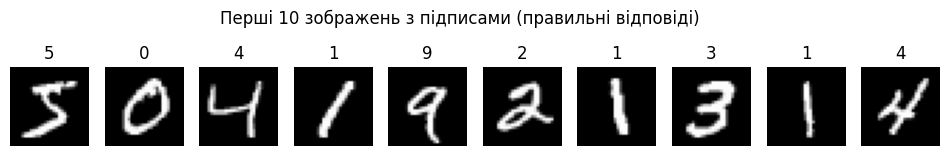

In [3]:
# Показуємо перші 10 прикладів з правильними підписами
plt.figure(figsize=(12, 2))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(str(y_train[i]))
    plt.axis('off')
plt.suptitle('Перші 10 зображень з підписами (правильні відповіді)')
plt.show()

## 4. Нормалізація даних

In [4]:
# Пікселі мають значення 0..255 — ділимо на 255, щоб отримати 0..1 (мережа навчається швидше)
x_train = x_train / 255.0
x_test  = x_test  / 255.0
print('Готово! Діапазон значень тепер від', x_train.min(), 'до', x_train.max())

Готово! Діапазон значень тепер від 0.0 до 1.0


## 5. Побудова нейронної мережі
Допоміжна функція `build_model` дозволяє швидко створювати мережі з різною кількістю прихованих шарів і нейронів — вона знадобиться для самостійних завдань.

In [5]:
def build_model(hidden_layers=(128,)):
    """Створює і компілює мережу: вхід 28x28 -> приховані шари ReLU -> 10 виходів softmax."""
    layers = [keras.Input(shape=(28, 28)),
              keras.layers.Flatten()]                      # 28x28 -> вектор з 784 чисел
    for n in hidden_layers:                                # приховані шари
        layers.append(keras.layers.Dense(n, activation='relu'))
    layers.append(keras.layers.Dense(10, activation='softmax'))  # по нейрону на кожну цифру 0-9
    model = keras.Sequential(layers)
    model.compile(optimizer='adam',                        # алгоритм оновлення ваг
                  loss='sparse_categorical_crossentropy',  # функція помилки для міток-чисел
                  metrics=['accuracy'])                    # відстежуємо точність
    return model

model = build_model((128,))
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Навчання мережі (5 епох)

In [6]:
history = model.fit(
    x_train, y_train,
    epochs=5,              # скільки разів мережа переглядає всі навчальні приклади
    batch_size=32,         # скільки прикладів обробляється за один крок оновлення ваг
    validation_split=0.1   # 10% навчальних даних відкладаємо для перевірки
)
print('Навчання завершено!')

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9239 - loss: 0.2672 - val_accuracy: 0.9632 - val_loss: 0.1248
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9648 - loss: 0.1164 - val_accuracy: 0.9705 - val_loss: 0.0994
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9764 - loss: 0.0801 - val_accuracy: 0.9705 - val_loss: 0.0950
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9820 - loss: 0.0606 - val_accuracy: 0.9740 - val_loss: 0.0900
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9869 - loss: 0.0455 - val_accuracy: 0.9753 - val_loss: 0.0889
Навчання завершено!


## 7. Оцінка точності на тестових даних

In [7]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
print(f'Точність на тестових даних: {test_accuracy * 100:.2f}%')
print(f'Помилка (loss):             {test_loss:.4f}')

Точність на тестових даних: 97.27%
Помилка (loss):             0.0888


## 8. Графіки навчання

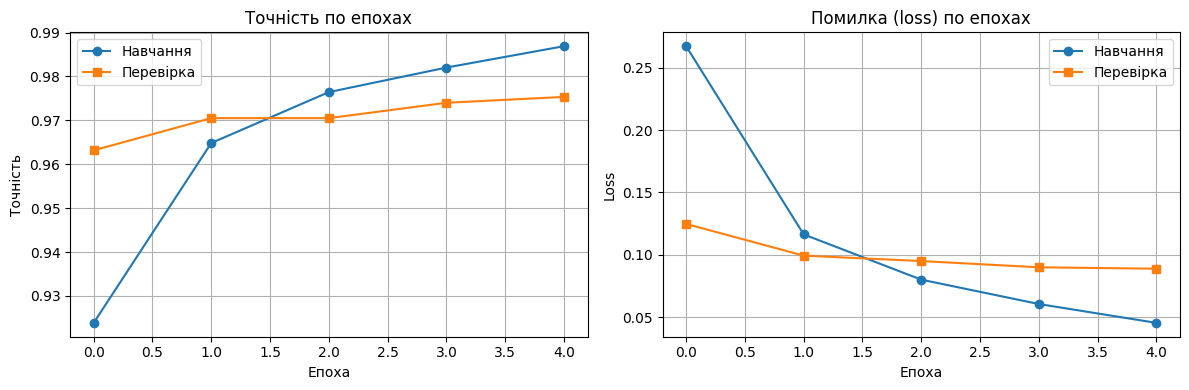

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history['accuracy'], 'o-', label='Навчання')
ax[0].plot(history.history['val_accuracy'], 's-', label='Перевірка')
ax[0].set_title('Точність по епохах'); ax[0].set_xlabel('Епоха'); ax[0].set_ylabel('Точність')
ax[1].plot(history.history['loss'], 'o-', label='Навчання')
ax[1].plot(history.history['val_loss'], 's-', label='Перевірка')
ax[1].set_title('Помилка (loss) по епохах'); ax[1].set_xlabel('Епоха'); ax[1].set_ylabel('Loss')
for a in ax: a.legend(); a.grid(True)
plt.tight_layout(); plt.show()

## 9. Перевірка на конкретних прикладах

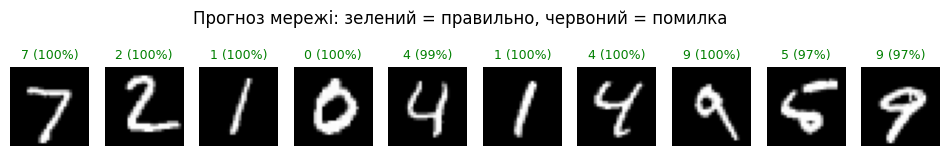

In [9]:
predictions = model.predict(x_test[:10], verbose=0)   # ймовірності для 10 класів

plt.figure(figsize=(12, 2))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(x_test[i], cmap='gray')
    predicted = np.argmax(predictions[i])              # клас з найбільшою ймовірністю
    color = 'green' if predicted == y_test[i] else 'red'
    plt.title(f'{predicted} ({predictions[i].max()*100:.0f}%)', color=color, fontsize=9)
    plt.axis('off')
plt.suptitle('Прогноз мережі: зелений = правильно, червоний = помилка')
plt.show()

---
# Завдання для самостійного виконання
Для чесного порівняння всі експерименти запускаються однаковою функцією `run_experiment` з тим самим зерном генератора.

In [10]:
results = []   # сюди збираємо результати всіх експериментів

def run_experiment(name, hidden=(128,), epochs=5, n_train=None, n_test=None, val_split=0.1):
    """Навчає мережу з заданими параметрами і повертає (модель, історію)."""
    keras.utils.set_random_seed(42)
    xtr, ytr = x_train[:n_train], y_train[:n_train]   # None = вся вибірка
    xte, yte = x_test[:n_test],  y_test[:n_test]
    m = build_model(hidden)
    h = m.fit(xtr, ytr, epochs=epochs, batch_size=32, validation_split=val_split, verbose=0)
    loss, acc = m.evaluate(xte, yte, verbose=0)
    results.append(dict(name=name, hidden=str(hidden), epochs=epochs, train=len(xtr), test=len(xte),
                        params=m.count_params(), train_acc=h.history['accuracy'][-1],
                        val_acc=h.history['val_accuracy'][-1], test_acc=acc, test_loss=loss))
    print(f'{name:<34} | тест: {acc*100:.2f}% | loss {loss:.4f} | параметрів {m.count_params():,}')
    return m, h

# Базовий варіант (як у кроках 1-9) — точка відліку для порівняння
base_model, base_hist = run_experiment('Базова: 128 нейронів, 5 епох')

Базова: 128 нейронів, 5 епох       | тест: 97.27% | loss 0.0888 | параметрів 101,770


### Завдання 1. Зміна розміру навчальної/тестової вибірки та кількості переглядів (епох)

In [11]:
# Менші вибірки: 10 000 / 30 000 навчальних, 2 000 / 5 000 тестових; різна кількість епох і частка перевірки
run_experiment('Вибірка 10k/2k, 5 епох',  n_train=10000, n_test=2000)
run_experiment('Вибірка 10k/2k, 15 епох', n_train=10000, n_test=2000, epochs=15)
run_experiment('Вибірка 30k/5k, 5 епох',  n_train=30000, n_test=5000)
run_experiment('Вся вибірка, val 20%, 3 епохи', epochs=3, val_split=0.2);

Вибірка 10k/2k, 5 епох             | тест: 92.15% | loss 0.2461 | параметрів 101,770
Вибірка 10k/2k, 15 епох            | тест: 94.25% | loss 0.2140 | параметрів 101,770
Вибірка 30k/5k, 5 епох             | тест: 95.58% | loss 0.1452 | параметрів 101,770
Вся вибірка, val 20%, 3 епохи      | тест: 97.04% | loss 0.0986 | параметрів 101,770


### Завдання 2. 64 нейрони у прихованому шарі замість 128

In [12]:
m64, h64 = run_experiment('64 нейрони, 5 епох', hidden=(64,))

64 нейрони, 5 епох                 | тест: 97.00% | loss 0.0984 | параметрів 50,890


### Завдання 3. 10 епох замість 5

128 нейронів, 10 епох              | тест: 97.28% | loss 0.1062 | параметрів 101,770


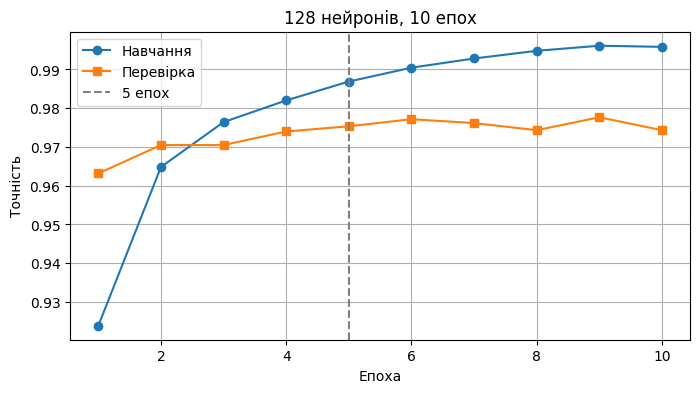

In [13]:
m10, h10 = run_experiment('128 нейронів, 10 епох', epochs=10)

plt.figure(figsize=(8, 4))
plt.plot(range(1, 11), h10.history['accuracy'], 'o-', label='Навчання')
plt.plot(range(1, 11), h10.history['val_accuracy'], 's-', label='Перевірка')
plt.axvline(5, color='gray', ls='--', label='5 епох')
plt.title('128 нейронів, 10 епох'); plt.xlabel('Епоха'); plt.ylabel('Точність')
plt.legend(); plt.grid(True); plt.show()

### Завдання 4. Додатковий прихований шар Dense(64, relu)

In [14]:
m2l, h2l = run_experiment('2 шари: 128 + 64, 5 епох', hidden=(128, 64))
m2l.summary()

2 шари: 128 + 64, 5 епох           | тест: 97.34% | loss 0.0966 | параметрів 109,386


Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_8 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 328,160 (1.25 MB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 218,774 (854.59 KB)

### Порівняння результатів

,Експеримент,Навч.,Тест,Епох,Параметрів,"Точн. навч., %","Точн. перев., %","Точн. тест, %",Loss тест
0,"Базова: 128 нейронів, 5 епох",60000,10000,5,101770,98.69,97.53,97.27,0.0888
1,"Вибірка 10k/2k, 5 епох",10000,2000,5,101770,97.00,94.70,92.15,0.2461
2,"Вибірка 10k/2k, 15 епох",10000,2000,15,101770,99.98,95.10,94.25,0.2140
3,"Вибірка 30k/5k, 5 епох",30000,5000,5,101770,98.39,95.83,95.58,0.1452
4,"Вся вибірка, val 20%, 3 епохи",60000,10000,3,101770,97.50,97.08,97.04,0.0986
5,"64 нейрони, 5 епох",60000,10000,5,50890,97.97,97.32,97.00,0.0984
6,"128 нейронів, 10 епох",60000,10000,10,101770,99.58,97.43,97.28,0.1062
7,"2 шари: 128 + 64, 5 епох",60000,10000,5,109386,98.72,97.77,97.34,0.0966


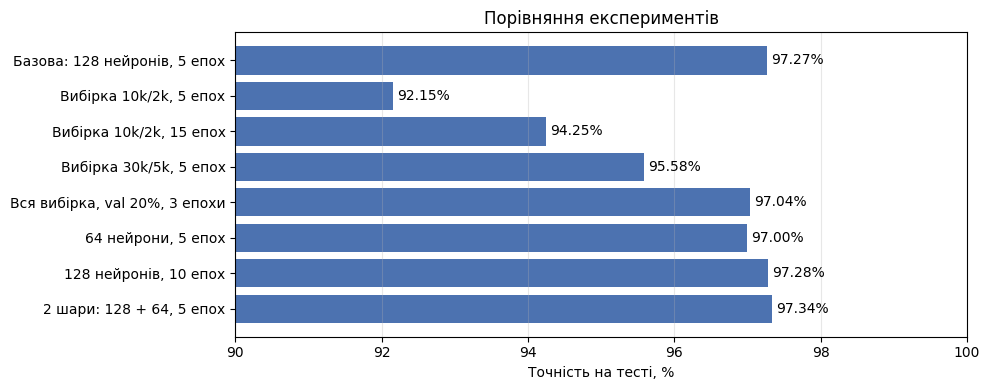

In [15]:
import pandas as pd
df = pd.DataFrame(results)
show = df[['name', 'train', 'test', 'epochs', 'params', 'train_acc', 'val_acc', 'test_acc', 'test_loss']].copy()
for c in ['train_acc', 'val_acc', 'test_acc']:
    show[c] = (show[c] * 100).round(2)
show['test_loss'] = show['test_loss'].round(4)
show.columns = ['Експеримент', 'Навч.', 'Тест', 'Епох', 'Параметрів', 'Точн. навч., %', 'Точн. перев., %', 'Точн. тест, %', 'Loss тест']
display(show)

plt.figure(figsize=(10, 4))
bars = plt.barh(show['Експеримент'], show['Точн. тест, %'], color='#4C72B0')
plt.bar_label(bars, fmt='%.2f%%', padding=3)
plt.xlim(90, 100); plt.xlabel('Точність на тесті, %'); plt.gca().invert_yaxis()
plt.title('Порівняння експериментів'); plt.grid(axis='x', alpha=.3); plt.tight_layout(); plt.show()

### Завдання 5. Приклади, де мережа помилилась

Помилок: 272 з 10000 (2.72%)


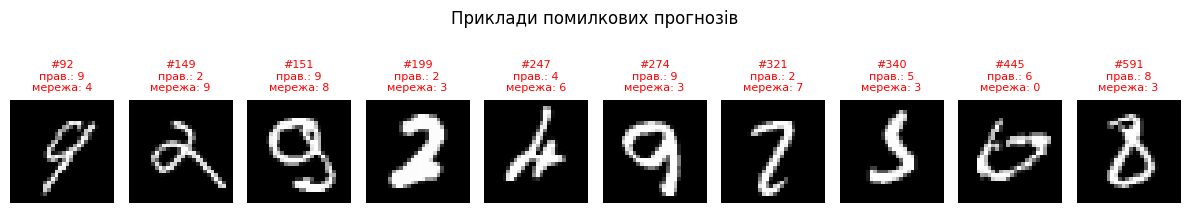

In [16]:
pred = np.argmax(m10.predict(x_test, verbose=0), axis=1)   # прогнози найкращої моделі для всього тесту
wrong = np.where(pred != y_test)[0]                          # індекси помилок
print(f'Помилок: {len(wrong)} з {len(y_test)} ({len(wrong)/len(y_test)*100:.2f}%)')

plt.figure(figsize=(12, 2.6))
for k, i in enumerate(wrong[:10]):
    plt.subplot(1, 10, k + 1)
    plt.imshow(x_test[i], cmap='gray')
    plt.title(f'#{i}\nправ.: {y_test[i]}\nмережа: {pred[i]}', color='red', fontsize=8)
    plt.axis('off')
plt.suptitle('Приклади помилкових прогнозів')
plt.tight_layout(); plt.show()

### Додатково: матриця помилок
Показує, які цифри мережа плутає між собою найчастіше.

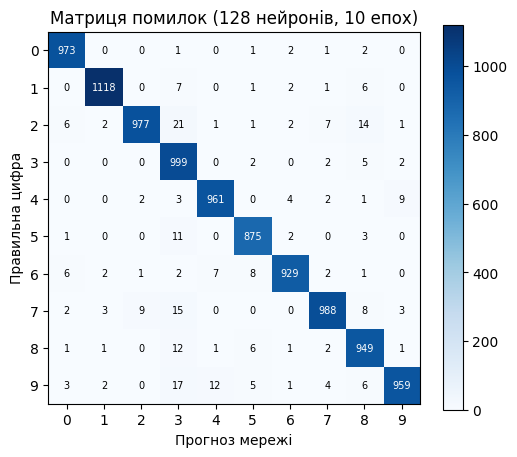

Модель збережено у mnist_model.keras


In [17]:
cm = tf.math.confusion_matrix(y_test, pred).numpy()
plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap='Blues')
for r in range(10):
    for c in range(10):
        plt.text(c, r, cm[r, c], ha='center', va='center', fontsize=7,
                 color='white' if cm[r, c] > cm.max() / 2 else 'black')
plt.xticks(range(10)); plt.yticks(range(10))
plt.xlabel('Прогноз мережі'); plt.ylabel('Правильна цифра'); plt.title('Матриця помилок (128 нейронів, 10 епох)')
plt.colorbar(); plt.show()

# Збереження навченої моделі, щоб використовувати її без повторного навчання
m10.save('mnist_model.keras')
print('Модель збережено у mnist_model.keras')

## Висновки
Висновки з конкретними числами наведено у звіті; цифри беруться з таблиці «Порівняння результатів» вище.